# Canaries: does Skeptic catch false discoveries?

Each canary runs on simulated data where the truth is known. The full-size results and charts come from `studies/canaries.py`; this notebook re-runs the quick ones live and shows the saved charts for the rest.

In [1]:
import json
from pathlib import Path
from IPython.display import Image, display
import numpy as np
from skeptic import canaries
REPORTS = Path('..') / 'reports'

## 1. Noise canary
1,000 zero-skill strategies with fat-tailed returns. About 5% should pass an uncorrected 5% test; almost none should survive correction.

In [2]:
r = canaries.noise_canary(n_strategies=1000, n_obs=1260, seed=0)
print({k: f'{v:.1%}' for k, v in r.pass_rate.items()})
print(f'best of 1,000: annual Sharpe {r.best_sr * np.sqrt(252):.2f}, PSR {r.best_psr:.3f}, DSR {r.best_dsr:.3f}')

{'none': '4.1%', 'bonferroni': '0.0%', 'holm': '0.0%', 'bh': '0.0%'}
best of 1,000: annual Sharpe 1.23, PSR 0.997, DSR 0.320


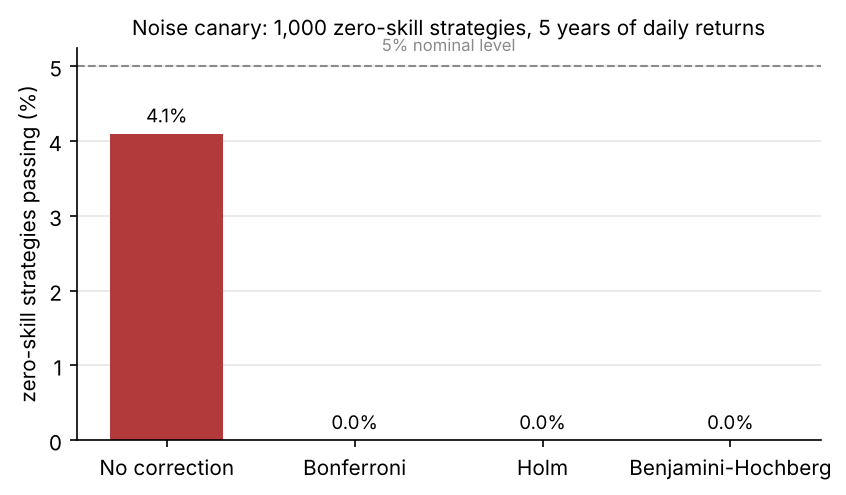

In [3]:
display(Image(REPORTS / 'canary_noise.png', width=640))

## 2. Leakage canary
A lookahead feature and overlapping labels, both on a random walk where the true accuracy is 50%.

{
  "mean_accuracy": {
    "naive_cv_lookahead": 0.6455833333333334,
    "pit_aligned_lookahead": 0.4967833333333333,
    "shuffled_kfold_overlap": 0.7609,
    "purged_kfold_overlap": 0.4975833333333334
  },
  "sd": {
    "naive_cv_lookahead": 0.005279546487257321,
    "pit_aligned_lookahead": 0.008653852706550239,
    "shuffled_kfold_overlap": 0.00892505835648522,
    "purged_kfold_overlap": 0.009061594782376892
  },
  "n_seeds": 10
}


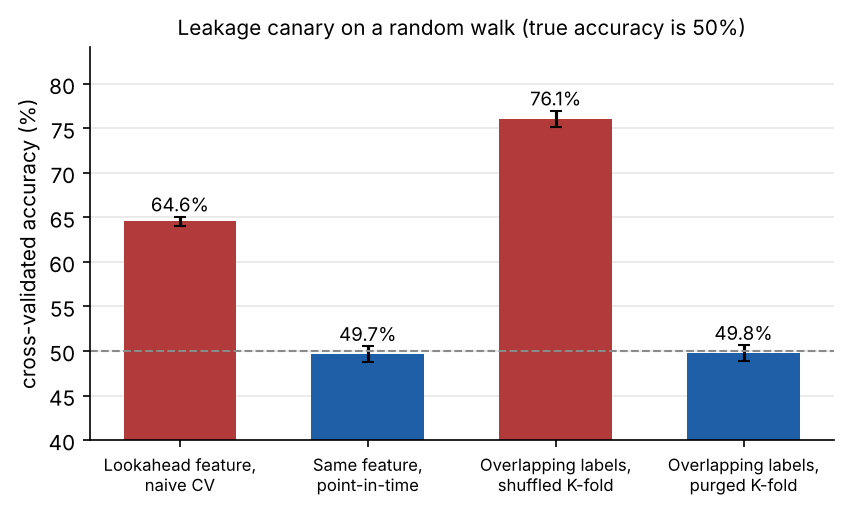

In [4]:
print(json.dumps(json.loads((REPORTS / 'canaries.json').read_text())['leakage'], indent=2))
display(Image(REPORTS / 'canary_leakage.png', width=640))

## 3. Planted signal: power
How often a real edge is detected, alone and as the best of 100 trials.

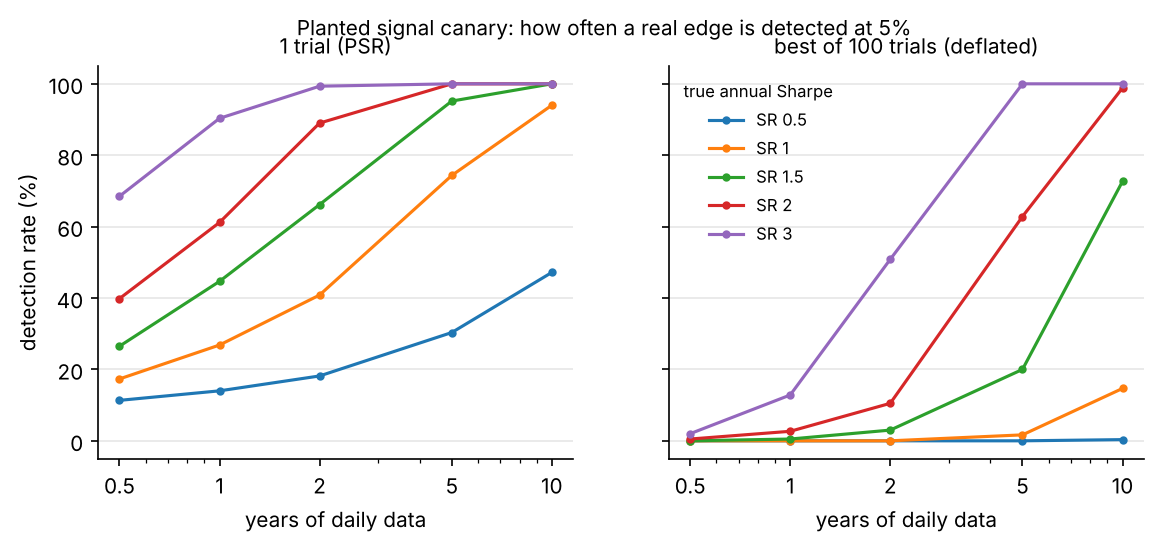

In [5]:
display(Image(REPORTS / 'canary_power.png', width=820))

## 4. Best of N
The best in-sample Sharpe of N zero-skill strategies grows with N exactly as the False Strategy Theorem predicts; the deflated Sharpe of the winner stays near 0.5.

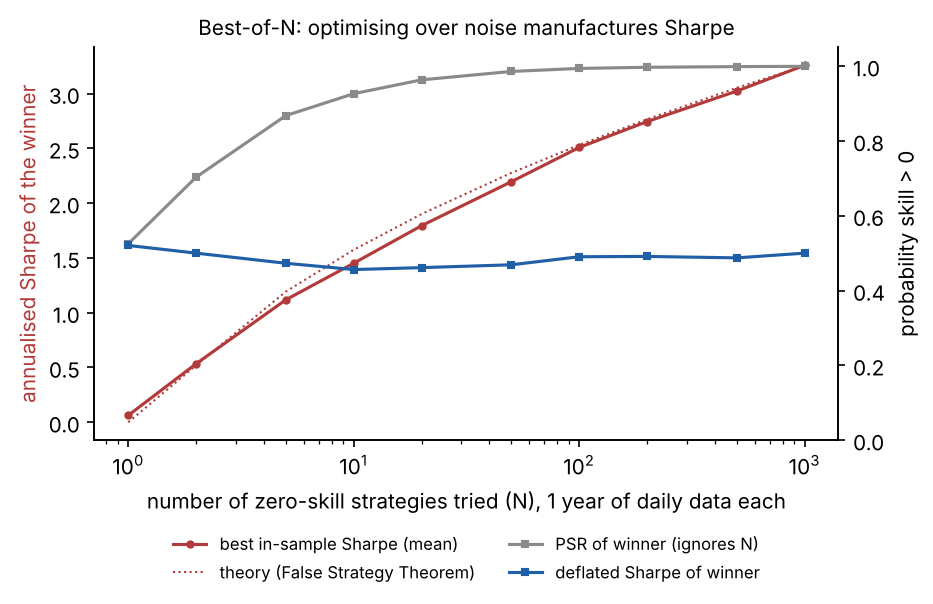

In [6]:
display(Image(REPORTS / 'canary_best_of_n.png', width=640))